In [4]:
import os, glob, hashlib, random, numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices('GPU'))  # Runtime > GPU

2.21.0 []


In [1]:
from google.colab import files
files.upload()   # pilih kaggle.json BARU
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vinayakshanawad/meat-freshness-image-dataset -p /content/data --unzip
!find /content/data -maxdepth 3 -type d

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/vinayakshanawad/meat-freshness-image-dataset
License(s): CC0-1.0
100% 59.4M/59.4M [00:00<00:00, 135MB/s]

/content/data
/content/data/Meat Freshness.v1-new-dataset.multiclass
/content/data/Meat Freshness.v1-new-dataset.multiclass/valid
/content/data/Meat Freshness.v1-new-dataset.multiclass/train


Pre Processing

In [14]:
import os
import glob
import hashlib
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
DATA_DIR = "/content/data/Meat Freshness.v1-new-dataset.multiclass"
exts = ("jpg", "jpeg", "png")

# Recursively gather all images
all_files = [f for e in exts for f in glob.glob(f"{DATA_DIR}/**/*.{e}", recursive=True)
                              + glob.glob(f"{DATA_DIR}/**/*.{e.upper()}", recursive=True)]

def md5(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()

# Deduplicate and extract correct class labels from filename
seen, paths, labels_txt = set(), [], []
for p in sorted(all_files):
    filename = os.path.basename(p)
    # Extract class from filename prefix (e.g., FRESH, HALF-FRESH, SPOILED)
    if "-" not in filename:
        continue
    class_name = filename.split("-")[0].upper()
    if class_name not in ("FRESH", "HALF", "SPOILED"):
        continue
    if class_name == "HALF":
        class_name = "HALF-FRESH"

    h = md5(p)
    if h in seen: continue
    seen.add(h)
    paths.append(p)
    labels_txt.append(class_name)

print(f"Total file: {len(all_files)} | Setelah dedup: {len(paths)}")

class_names = sorted(set(labels_txt))     # ['FRESH', 'HALF-FRESH', 'SPOILED']
print("Correct classes found:", class_names)
cls2idx = {c: i for i, c in enumerate(class_names)}
y = np.array([cls2idx[l] for l in labels_txt])
paths = np.array(paths)

# Split stratified: 70% train, 15% val, 15% test
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, y, test_size=0.30, stratify=y, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"Train size: {len(p_train)} | Val size: {len(p_val)} | Test size: {len(p_test)}")
assert not (set(p_train) & set(p_val) | set(p_train) & set(p_test) | set(p_val) & set(p_test))

Total file: 2266 | Setelah dedup: 2266
Correct classes found: ['FRESH', 'HALF-FRESH', 'SPOILED']
Train size: 1586 | Val size: 340 | Test size: 340


In [16]:
IMG, BATCH, NUM_CLASSES = 224, 32, len(class_names)
AUTOTUNE = tf.data.AUTOTUNE

print(f"Setting up datasets with NUM_CLASSES = {NUM_CLASSES} (Classes: {class_names})")

def load_img(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG, IMG))            # float32, 0-255
    return img, tf.one_hot(label, NUM_CLASSES)

def make_ds(p, y, training):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training: ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_img, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, True)
val_ds   = make_ds(p_val,   y_val,   False)
test_ds  = make_ds(p_test,  y_test,  False)   # JANGAN disentuh sampai evaluasi akhir

cw = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(cw)); print("Updated Class Weights:", class_weight)

Setting up datasets with NUM_CLASSES = 3 (Classes: ['FRESH', 'HALF-FRESH', 'SPOILED'])
Updated Class Weights: {0: np.float64(0.8855388051367951), 1: np.float64(0.9577294685990339), 2: np.float64(1.2097635392829902)}


In [7]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.2, value_range=(0, 1)),
    layers.RandomContrast(0.2),
], name="augmentation")

Extraction Data

In [8]:
def channel_shuffle(x, groups=2):
    _, h, w, c = x.shape
    x = layers.Reshape((h, w, groups, c // groups))(x)
    x = layers.Permute((1, 2, 4, 3))(x)
    return layers.Reshape((h, w, c))(x)

WD = 4e-5  # L2 kecil pada kernel conv (tambahan weight decay)
def conv_bn(x, f, k=1, s=1, act=True):
    x = layers.Conv2D(f, k, strides=s, padding="same", use_bias=False,
                      kernel_regularizer=keras.regularizers.l2(WD))(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x) if act else x

def dw_bn(x, s=1):
    x = layers.DepthwiseConv2D(3, strides=s, padding="same", use_bias=False,
                               depthwise_regularizer=keras.regularizers.l2(WD))(x)
    return layers.BatchNormalization()(x)

def shuffle_unit_s1(x):                      # stride 1: split -> branch -> concat -> shuffle
    c = x.shape[-1]
    x1 = layers.Lambda(lambda t: t[..., : c // 2])(x)
    x2 = layers.Lambda(lambda t: t[..., c // 2 :])(x)
    x2 = conv_bn(x2, c // 2)
    x2 = dw_bn(x2)
    x2 = conv_bn(x2, c // 2)
    return channel_shuffle(layers.Concatenate()([x1, x2]))

def shuffle_unit_s2(x, out_c):               # stride 2: downsampling
    b1 = dw_bn(x, s=2);  b1 = conv_bn(b1, out_c // 2)
    b2 = conv_bn(x, out_c // 2);  b2 = dw_bn(b2, s=2);  b2 = conv_bn(b2, out_c // 2)
    return channel_shuffle(layers.Concatenate()([b1, b2]))

def build_backbone(x, stage_channels=(48, 96, 192), repeats=(4, 8, 4), last_c=1024):
    x = conv_bn(x, 24, k=3, s=2)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)
    for out_c, r in zip(stage_channels, repeats):
        x = shuffle_unit_s2(x, out_c)
        for _ in range(r - 1):
            x = shuffle_unit_s1(x)
    x = conv_bn(x, last_c)
    return layers.GlobalAveragePooling2D(name="feature_vector")(x)

Model

In [17]:
inputs = keras.Input((IMG, IMG, 3))
x = layers.Rescaling(1.0 / 255)(inputs)        # normalisasi 0-1 (catat untuk app Flutter!)
x = augment(x)                                  # nonaktif otomatis saat inference
feat = build_backbone(x)
x = layers.Dropout(0.5)(feat)
outputs = layers.Dense(NUM_CLASSES, activation="softmax",
                       kernel_regularizer=keras.regularizers.l2(1e-3))(x)
model = keras.Model(inputs, outputs, name="ShuffleNetV2_0.5x")

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"],
)
model.summary()

Model: "ShuffleNetV2_0.5x"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ rescaling_1[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 112, 112,  │        648 │ augmentation[1][… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │         96 │ conv2d_37[0][0]   │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_37 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ re_lu_37[0][0]    │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 56, 56,    │        576 │ max_pooling2d_1[… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │         96 │ conv2d_39[0][0]   │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_39 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_19 │ (None, 28, 28,    │        216 │ max_pooling2d_1[… │
│ (DepthwiseConv2D)   │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_20 │ (None, 28, 28,    │        216 │ re_lu_39[0][0]    │
│ (DepthwiseConv2D)   │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │         96 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │         96 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 28, 28,    │        576 │ batch_normalizat… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 28, 28,    │        576 │ batch_normalizat… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │         96 │ conv2d_38[0][0] 

 Total params: 352,819 (1.35 MB)

 Trainable params: 344,867 (1.32 MB)

 Non-trainable params: 7,952 (31.06 KB)

In [19]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=5, min_lr=1e-6, verbose=1),
]

history = model.fit(
    train_ds, validation_data=val_ds,
    epochs=20, class_weight=class_weight, callbacks=callbacks,
)

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.7087 - loss: 0.8892 - val_accuracy: 0.3765 - val_loss: 2.0939 - learning_rate: 0.0010
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.6999 - loss: 0.8682 - val_accuracy: 0.3765 - val_loss: 2.2516 - learning_rate: 0.0010
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 0.7081 - loss: 0.8583 - val_accuracy: 0.3765 - val_loss: 2.2385 - learning_rate: 0.0010
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.7251 - loss: 0.8449 - val_accuracy: 0.3765 - val_loss: 2.6300 - learning_rate: 0.0010
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.7402 - loss: 0.8157 - val_accuracy: 0.3765 - val_loss: 2.3402 - learning_rate: 0.0010
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7599 - loss: 0.8122
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
50/50 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.7623 - loss: 0.8150 - val_accura

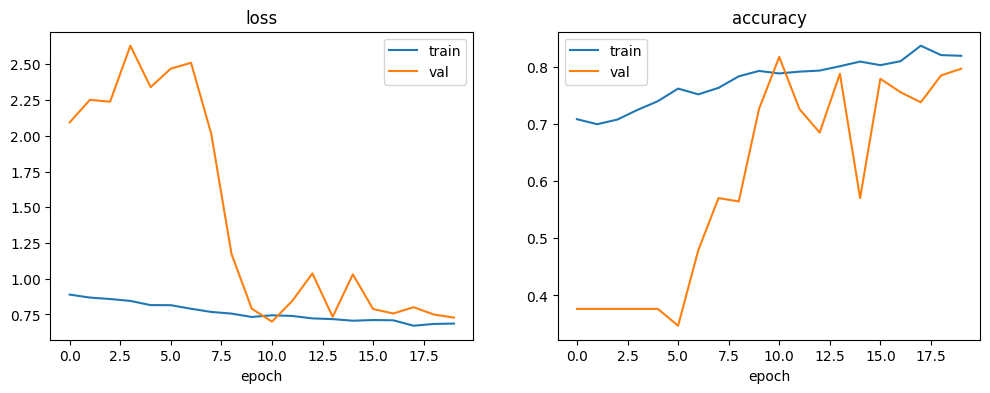

In [20]:
def plot_history(h):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ["loss", "accuracy"]):
        a.plot(h.history[m], label="train"); a.plot(h.history[f"val_{m}"], label="val")
        a.set_title(m); a.set_xlabel("epoch"); a.legend()
    plt.show()
plot_history(history)

11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 955ms/step - accuracy: 0.8029 - loss: 0.7212
Test accuracy: 0.8029
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 685ms/step
              precision    recall  f1-score   support

       FRESH     0.8189    0.8125    0.8157       128
  HALF-FRESH     0.7250    0.7311    0.7280       119
     SPOILED     0.8817    0.8817    0.8817        93

    accuracy                         0.8029       340
   macro avg     0.8085    0.8084    0.8085       340
weighted avg     0.8032    0.8029    0.8031       340



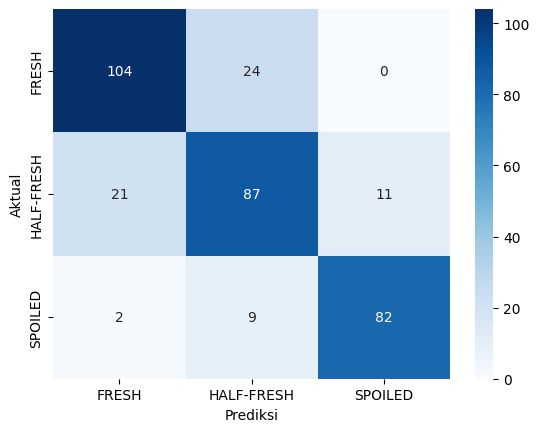

In [21]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_prob = model.predict(test_ds)
y_pred = y_prob.argmax(1)
y_true = np.concatenate([np.argmax(b, 1) for _, b in test_ds])

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.show()

In [22]:
tr_h = {md5(p) for p in p_train}
te_h = {md5(p) for p in p_test}
print("Duplikat train↔test:", len(tr_h & te_h))   # harus 0

Duplikat train↔test: 0


In [23]:
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]       # dynamic range quantization
open("meatfresh_model.tflite", "wb").write(conv.convert())
open("labels.txt", "w").write("\n".join(class_names))  # urutan label harus sama persis

Saved artifact at '/tmp/tmpxxhlr8do'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_305')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  138687685749328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687685746064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687685745872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687685744720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687685749520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687684631952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687684634064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687684633872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687684634256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138687684625424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386876846

24